#**Modulo V Imágenes en salud**

Dras. Valeria Rulloni- Carolina Maldonado

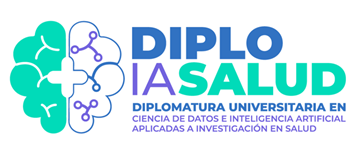

 **Diplomatura en Ciencia de Datos e Inteligencia Artificial
Aplicada a la Investigación en Salud**
Sitio web: https://diploiasalud.sitios.fcm.unc.edu.ar/

# Temario a desarrollar:


1. Imágenes digitales. Estructura. Tipo de dato: float,
uint8, logical. Imágenes binarias, monocromáticas, a color.
2. **Histograma. Mejora de la imagen:Transformaciones punto a punto,Umbralado y Binarización.**
3. Ruido. Filtros. Noción de Vecindad. Filtros lineales. Filtros estadísticos.
4. Práctica integral: Mejora y segmentación. Algoritmos de ML en imágenes (Introducción)


**Recomendación:**
+ Antes que nada **realice una copia de este archivo y trabaje en ella** . Guárdelo en la misma carpeta de preferencia (si está en Colaboratory lo guarda por defecto en la carpeta Colaboratory del drive, se puede reubicar).

# 1 Histograma. Concepto.

 Es una representación de la distribución de los niveles de grises en una imagen.

 Dado un determinado nivel de gris, el histograma muestra la cantidad de píxeles que tienen dicha intensidad.

 Muestra gráficamente el vector de frecuencias de las intensidades presentes en la imagen.



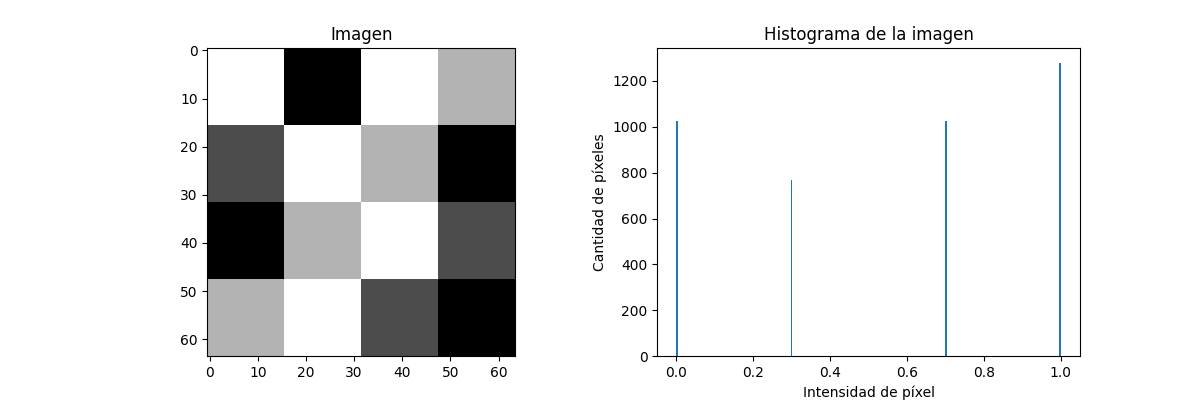

https://docs.opencv.org/3.4/d8/dbc/tutorial_histogram_calculation.html

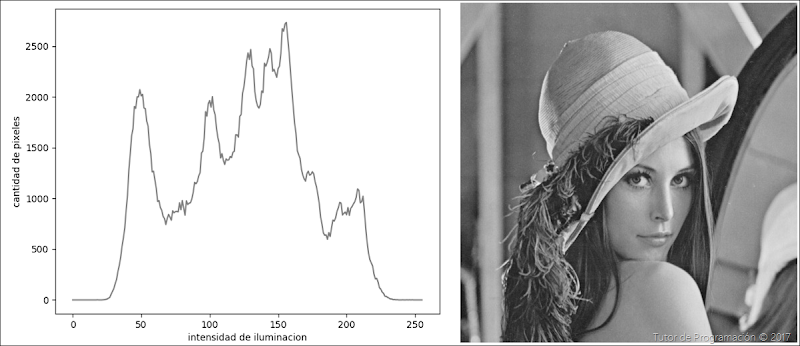

Analizamos histograma vs imagen.


## 1.1 Observaciones sobre Histogramas




*   **Rango de intensidades de una imagen** es el intervalo de intensidades que alcanza dicha imagen, es decir [min, max].

* Cuando mayoria de las intensidades estan amontonadas y el  histograma esconcentrado se trata de imágenes con **poco contraste**.

* Cuando el rango de intensidades es grande y el histograma NO esta concentrado se trata de imágenes con mucho contraste.

* Cuando el histograma posee altos valores en los extremos de la escala (forma de “U”) la imagen está saturada.

* Cuando el histograma está corrido hacia la derecha, la imagen es clara

* Cuando el histograma está corrido hacia la izquierda, la imagen es oscura

Más ejemplos:
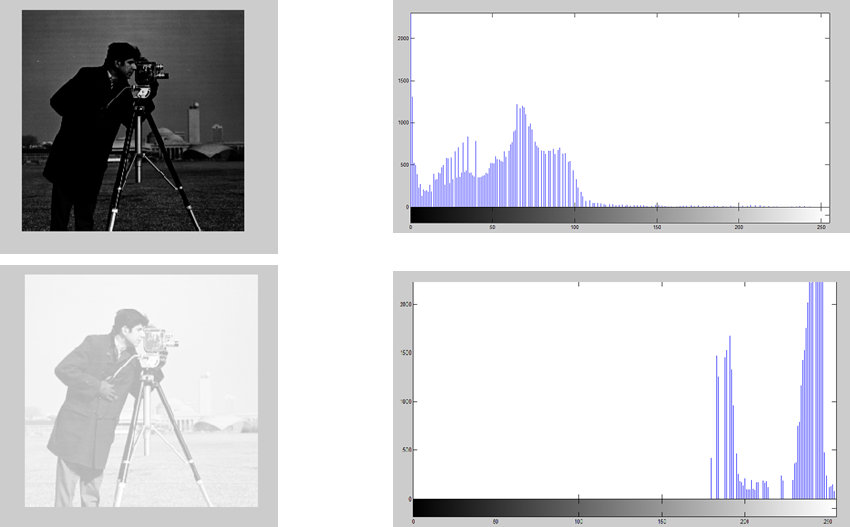

## 1.2 Bins
Los "bins" son subdivisiones consecutivas, no solapadas del rango de intensidades.

En el histograma puedo realizar el conteo de cada una de las intensidades o de "agrupamiento de las mismas".

Si tengo rango de intensidades de [0,255] y elijo 256 bins va a realizar el conteo de cada intensidad individual.

Pero si elijo 128 bins, va a agrupar las intesidades de a 2 y realizar el conteo de cada par de intesidades.([0,1],[2,3]...[254,255]

Cita: https://medium.com/python-pandemonium/data-visualization-in-python-histogram-in-matplotlib-dce38f49f89c






Histogramas con OpenCV (Monocroma o RGB):



**cv2.calcHist(images, channels, mask, histSize, ranges[, hist[, accumulate]])**

- Devuelve un vector
- El nombre de la imagen debe estar entre corchetes
- Channels indica para qué canal se pide el histograma. Puede ser 0, 1 o 2.
- Si la imagen es gris/monocroma se pone 0.
- Si el histograma es de la imagen completa se coloca como máscara None.
- Se puede pedir el histograma de una parte de la imagen, mediante una máscara.
- histsize indica la cantidad de bins. Si queremos contabilizar la frecuencia de todas las intensidades y tenemos 256 valores, colocamos 256 entre corchetes. Podemos agruparlos. Pedir por ejemplo 16 bins.
- ranges es el rango de valores que queremos contabilizar (no confundir con rango de intensidades). En nuestro caso, normalmente es [0,256]


aqui info sobre los prametros usados: https://docs.opencv.org/3.4/d6/dc7/group__imgproc__hist.html#ga4b2b5fd75503ff9e6844cc4dcdaed35d


#2 Histograma. Práctica.
Calculamos y graficamos histogramas imágenes.

Usamos los archivos:
- 'lunar.jpg',
- 'ortopanto_recorte.png'


##2.1 Histograma de imagen monocroma.

In [ ]:
#librerias necesarias
import cv2
import matplotlib.pyplot as plt

In [ ]:
#leemos la imagen con cv2
img = cv2.imread('ortopanto_recorte.png',0) #el valor 0 al lado abre una monocroma


In [ ]:
#miramos un poco como es la imagen
print(f"Tipo de matriz: {type(img)}")
print(f"Tipo de dato del píxel: {img.dtype}")
print(f"Tamaño de la imagen: {img.shape}")

Tipo de matriz: <class 'numpy.ndarray'>
Tipo de dato del píxel: uint8
Tamaño de la imagen: (397, 477)


In [ ]:
# Calculamos histograma usando OpenCV
# miramos que significa cada parametro en la docu
bins=256
hist = cv2.calcHist([img], [0], None, [bins], [0, 256])

In [ ]:
#miramos que tiene "hist"
print(f"Tipo de dato de hist: {type(hist)}")
print(f"Tipo de dato de hist: {hist.dtype}")
print(f"Tamaño de hist: {hist.shape}")
print(f"Contenido de hist: {hist[10:20]}")

Tipo de dato de hist: <class 'numpy.ndarray'>
Tipo de dato de hist: float32
Tamaño de hist: (256, 1)
Contenido de hist: [[ 832.]
 [ 848.]
 [1061.]
 [ 737.]
 [ 723.]
 [ 600.]
 [ 578.]
 [ 582.]
 [ 509.]
 [ 447.]]


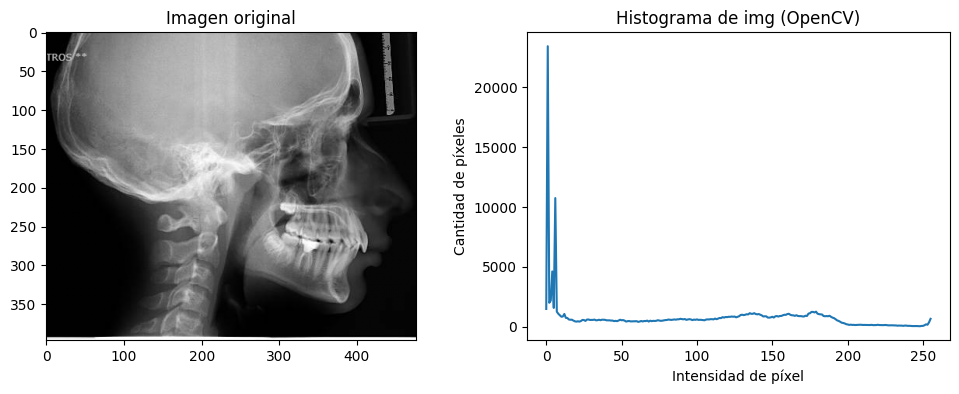

In [ ]:
#graficamos la imagen y al lado su histograma en una grilla de subplots

plt.figure(figsize=(12, 4)) #da tamaño a la figura
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Imagen original')

plt.subplot(1, 2, 2)
plt.plot(hist)
plt.title('Histograma de img (OpenCV)')
plt.xlabel('Intensidad de píxel')
plt.ylabel('Cantidad de píxeles')

#plt.ylim([0, 2000]) #jugamos aca con los limites del eje y
plt.show()

Conversamos un poco sobre lo que vemos en la imagen vs histograma y jugamos un poco con los limites del eje y (conteo)

## 2.2 Histogramas de los 3 canales de una RGB

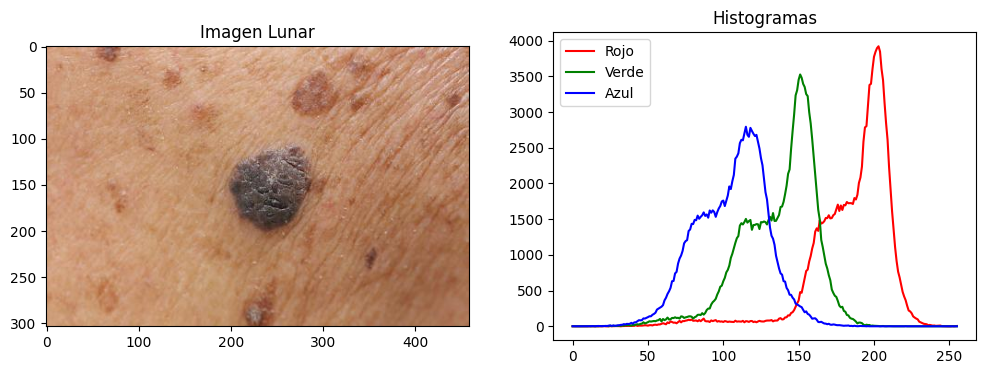

In [ ]:
#cargamos la imagen lunar

path='lunar.jpg'
# Recordemos que la imageb a color es leida por defecto como dato BGR y no RGB.
img2= cv2.imread(path) #dato BGR
img_rgb = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB) # lo paso a RGB

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title('Imagen Lunar')

plt.subplot(1, 2, 2)
color = ('r','g','b')
#en este ciclo for leo cada una de los canales y hago histograma para cada uno de ellos
for i, c in enumerate(color):
    hist = cv2.calcHist([img_rgb], [i], None, [256], [0, 256])
    plt.plot(hist, color = c)
    #plt.ylim([0,500])
plt.title('Histogramas')
plt.legend(['Rojo','Verde','Azul'])
plt.show()


#3 Mejora de la Imagen. Concepto

* Busca modificar la imagen original ya sea para  para acentuar algunas características relevantes de la imagen, como bordes o para mejorarlas como por ejemplo aumento de contraste. Esto implica un grado de juicio subjetivo acerca de la calidad resultante y depende de la imagen y de lo que se busca.

* Un método no es siempre útil para resolver todos los problemas similares.

* Los resultados pueden producir una imagen diferente a la original, se pueden sacrificar algunos aspectos para mejorar otros.

**Métodos de mejora según el dominio**

* Existen métodos en el Dominio Espacial o en el de Frecuencia, así como en otros dominios. En este módulo nos focalizaremos en el dominio espacial.
Considerando que una imagen monocromáticas 2D es una función  $f([i,j])$ en las posiciones, pensamos $$T: f → g$$

$$T(f[i,j])=g[i,j]$$

Donde  imagen $f([i,j])$ es la imagen de salida  y $g([i,j])$ la imagen g de llegada.            

                      
**Mejora punto a punto (lugar a lugar/ pixel a pixel):**
    
Si  $r=f(i,j) $ es la intensidad de la imagen de salida, entonces  $T(r)= g(i,j)$ es la intensidad de la imagen de llegada o imagen transformada.
    
            T: r ----->  T(r)
            
            r= nivel de gris de la imagen original y
            T(r)= nuevo valor, nivel de gris de la imagen modificada
            


**Las distintas operaciones punto a punto tienen distintos efectos en la imagen transformada:**

+ Modifican el rango de intensidades presentes en la imagen
+ Aclaran u oscurecen la imagen
+ Modifican su histograma de manera de "Ecualizarlo" y mejorar el contraste de la imagen
+ Binarizan la imagen para "segmentar zonas de interes"
etc.

## 3.1 Negativo de una Imagen
* $T(r)=255-r$, para unint8
* $T(r)=1-r$, para $0\leq r\leq 1$


## 3.2 Modificación del rango (o sea el intervalo de los valores de intensidades)

- llevarlo a [0 - 1]
$$ r \rightarrow T(r)=\frac{r-min}{max-min}$$

- llevarlo a [0 - 255]
para uint8
$$ r \rightarrow T(r)=\left\lfloor 255\frac{r-min}{max-min} \right\rfloor, \,\, \leftarrow \, floor, redondeo$$

- disminuir el rango

$$ r \rightarrow T(r)=c \log{(r+1)},\ r\geq 0 , \ c<1$$





## 3.3 Ecualización del histograma
La ecualización del histograma pretende una distribución uniforme de las intensidades. Esto mejora el contraste.

La libreria OpenCV lo hace con la funcion: cv2.equalizeHist()

## 3.4 Ajuste gamma. Aclarar u oscurecer imágenes.

Si tenemos el rango de intensidades $ 0\leq r \leq 1$, elegimos un exponente ${\gamma}$ y hacemos:

$$T(r)=r^{\gamma},$$



**Para Aclarar**

$$T(r)=r^{\gamma},\,\gamma <1$$

Por ejemplo $T(r)=r^{\frac{1}{2}}=\sqrt{r}$


**Para Oscurecer**

$$T(r)=r^{\gamma},\,\gamma >1$$


Por ejemplo $T(r)=r^{2}$ aqui $\gamma >1$

**Condición Importante**: el concepto de Ajuste Gamma lo explicamos para  intensidades $ 0\leq r \leq 1$. Para $ 0\leq r \leq 255$ se lo adapta primero llevando a $ 0\leq r \leq 1$.

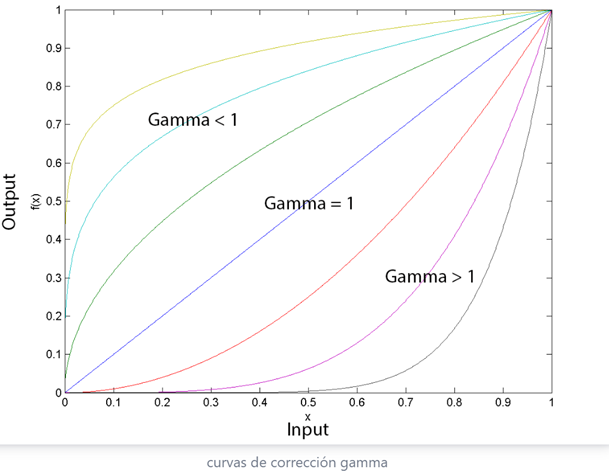

Leemos y cargamos la imagen monocroma de lunar y le hacemos correcciones gamma.

In [ ]:
#cargamos lunar monocroma
img_mono = cv2.imread('lunar.jpg',0) #imagen monocroma


In [ ]:
#importaciones para tener la funcion gamma y se la aplicamos a la imagen anterio
from skimage import data, exposure
gamma=0.01
img_ajuste = exposure.adjust_gamma(img_mono, gamma)# aca

In [ ]:
#miramos un poco el dato img_ajuste
print(f"Tipo de dato de img_ajuste: {type(img_ajuste)}")
print(f"Tipo de dato de img_ajuste: {img_ajuste.dtype}")
print(f"Tamaño de img_ajuste: {img_ajuste.shape}")
print(f"Algunas posiciones de img_ajuste: {img_ajuste[150:155,250:255]}")


Tipo de dato de img_ajuste: <class 'numpy.ndarray'>
Tipo de dato de img_ajuste: uint8
Tamaño de img_ajuste: (304, 459)
Algunas posiciones de img_ajuste: [[252 251 252 253 253]
 [252 251 252 252 252]
 [252 251 252 252 252]
 [251 252 252 252 252]
 [251 252 252 252 252]]


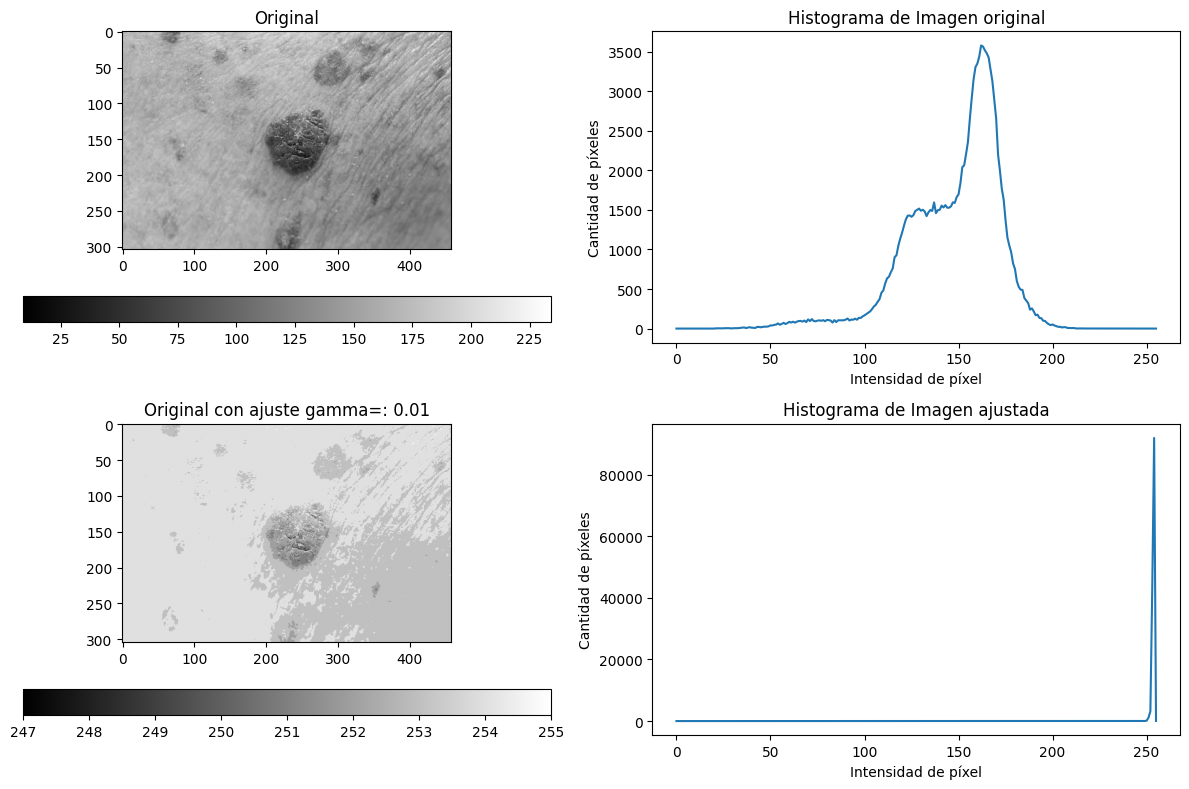

In [ ]:
#Calculamos los histogramas de la imagen original y la ajustada
hist_img = cv2.calcHist([img_mono], [0], None, [256], [0, 256])
hist_ajuste = cv2.calcHist([img_ajuste], [0], None, [256], [0, 256])

#Mostramos la imagen original y la ajustada o corregida y sus respectivos histogramas
#en un subplot de 2 filas y 2 columnas

plt.figure(figsize=(12,8))

plt.subplot(221),plt.imshow(img_mono ,cmap='gray')
plt.colorbar(orientation='horizontal')
plt.title('Original')

plt.subplot(222)
plt.plot(hist_img)
plt.title('Histograma de Imagen original')
#aqui ponemos título a los ejes
plt.xlabel('Intensidad de píxel')
plt.ylabel('Cantidad de píxeles')

plt.subplot(223),plt.imshow(img_ajuste ,cmap='gray')
plt.colorbar(orientation='horizontal'),
plt.title(f"Original con ajuste gamma=: {gamma}")


plt.subplot(224)
plt.plot(hist_ajuste)
plt.title('Histograma de Imagen ajustada')
#aqui ponemos título a los ejes
plt.xlabel('Intensidad de píxel')
plt.ylabel('Cantidad de píxeles')

plt.tight_layout() # Agrega esta línea antes de plt.show() en tus celdas de graficado para evitar la superposición de títulos.
plt.show()

**Ejercicio 5**. oscurecer la imagen de lunar . Mostrar imagen original y oscurecida.

## 3.5 Binarización por umbralizado

La binarización es una reducción de la resolución radiométrica o sea de la cantidad de intensidades presentes, ya que pasamos de [0,255] a {0,1}.


Transformación punto a punto, lugar a lugar
* Primero se define un valor de corte llamado $umbral$, con algún criterio (arbitrario, 0.3, media, Otsu, etc.) y se calcula en cada lugar:
 $$T(r)=\left\{
\begin{array}{lr}
  1& r\geq umbral\\
	0& r<umbral\\
\end{array}
\right.$$

*O su negativo:

$$T(r)=\left\{
\begin{array}{lr}
  0& r\geq umbral\\
	1& r<umbral\\
\end{array}
\right.$$




**¿Cómo elegimos el umbral?**
¡¡El histograma ayuda!!

**Binarizado con cv2.threshold**

OpenCV nos provee la función **cv2.threshold** para binarizar una imagen, una vez que hemos elegido (por algún método) dicho umbral.
Devuelve la imagen binaria y el umbral elegido


In [ ]:
umbral=100
#umbral=30
#umbral=150
umb,binaria = cv2.threshold(img_mono,umbral,255,cv2.THRESH_BINARY)
print(type(img_mono[0,0]),type(binaria[0,0]))
print(umb)

<class 'numpy.uint8'> <class 'numpy.uint8'>
100.0


In [ ]:
hist_binaria = cv2.calcHist([binaria], [0], None, [256], [0, 256])

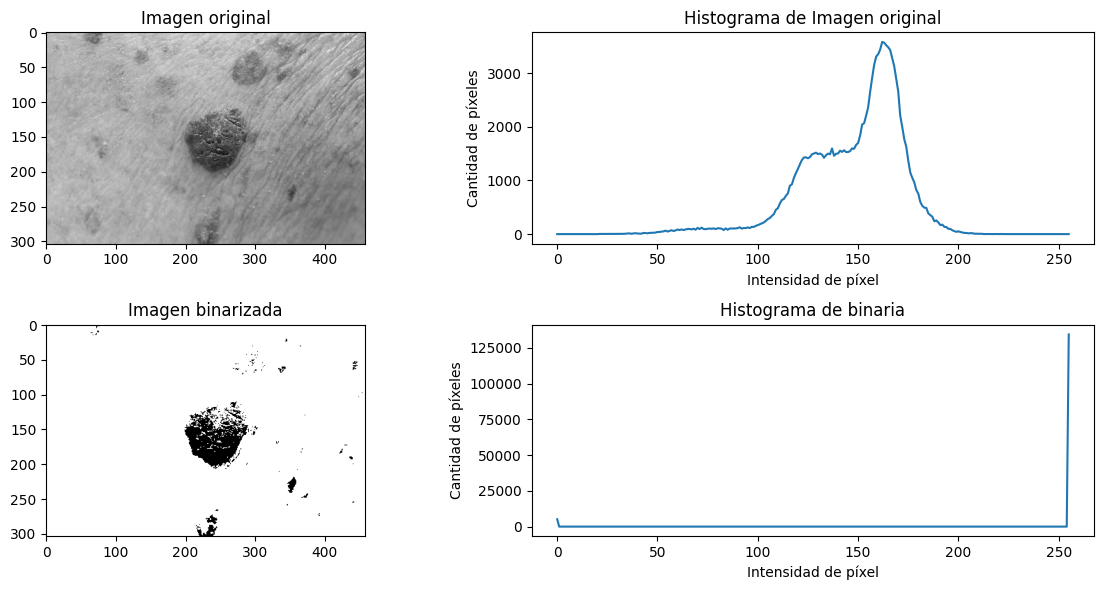

In [ ]:
plt.figure(figsize=(12, 6))
plt.subplot(2, 2, 1)
plt.imshow(img_mono, cmap='gray')
plt.title('Imagen original')

plt.subplot(2, 2, 2)
plt.plot(hist_img)
plt.title('Histograma de Imagen original')
plt.xlabel('Intensidad de píxel')
plt.ylabel('Cantidad de píxeles')

plt.subplot(2, 2, 3)
plt.imshow(binaria, cmap='gray')
plt.title('Imagen binarizada')

plt.subplot(2, 2, 4)
plt.plot(hist_binaria)
plt.title('Histograma de binaria')
plt.xlabel('Intensidad de píxel')
plt.ylabel('Cantidad de píxeles')

#plt.ylim([0, 2000]) #jugamos aca con los limites del eje y
plt.tight_layout()
plt.show()

**Ejercicio 6**

A partir de la imagen 'ortopanto_recorte.png', obtenga una imagen binaria intentando segmentar o aislar alguna región que considere relevante. Visualice original y binarizada.

### 3.5.1 Metodo Otsu para elección automática del umbral

Elige un umbral para separar los pixeles en 2 clases, intentando que *la varianza  en cada clase sea mínima y la varianza entre las 2 clases sea máxima.*

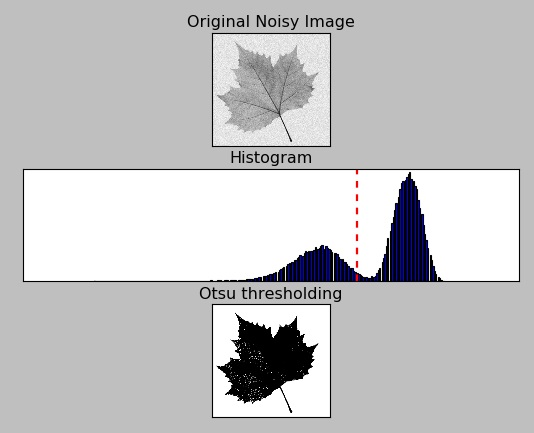


[Aqui](https://hbyacademic.medium.com/otsu-thresholding-4337710dc519) documentación más detallada

### 3.5.2 Binarización adaptativa (umbral local: media o media ponderada gaussiana, con offset)

En vez de usar un "umbral globlal" para toda la imagen, calcula un umbral diferente para pequeñas subregiones de la imagen (el tamaño cuadrado de la subregión es un parámetro). Es aconsejado en imágenes con iluminación variable.

[Aqui](https://opencv24-python-tutorials.readthedocs.io/en/latest/py_tutorials/py_imgproc/py_thresholding/py_thresholding.html) mas info

Umbral adaptativo. Sirve para imagenes con diferente tipo de iluminación.

**dst = cv2.adaptiveThreshold(src, maxValue, adaptiveMethod, thresholdType, blockSize, C)**

Parameters:

*   src: The source 8-bit single-channel grayscale
*   maxValue: The value assigned to pixels that satisfy the threshold condition (typically 255 for white).
* adaptiveMethod: Determines how the threshold for each region is calculated:
 cv2.ADAPTIVE_THRESH_MEAN_C: The threshold is the mean of the neighborhood area.
 cv2.ADAPTIVE_THRESH_GAUSSIAN_C: The threshold is a Gaussian-weighted sum of the neighborhood values.
* thresholdType: The type of thresholding to apply. It must be either:
cv2.THRESH_BINARY: Pixels above the threshold become maxValue; others become 0.
cv2.THRESH_BINARY_INV: Pixels above the threshold become 0; others become maxValue.
* blockSize: The size of the pixel neighborhood (e.g., 3, 5, 7). It must be an odd number greater than 1.
* C: A constant subtracted from the calculated mean or weighted mean. It is used to fine-tune the thresholding by filtering out noise.

 **Binarizamos a mano, con Otsu y de modo adaptativo y mostramos**

In [ ]:
#usamos cv2.threshold pero con el parametro de umbral automatico Otsu
umb_o,binaria_o = cv2.threshold(img_mono,0,255,cv2.THRESH_OTSU)
print(img.dtype,binaria_o.dtype,'umbral:',umb_o)

uint8 uint8 umbral: 141.0


In [ ]:
# usamos cv2.adaptiveThreshold para una binarización adaptativa
blockSize=15 #entero impar, pues se considera un área de ancho x ancho
C=5 #se le resta a la media para dar el umbral, mientras más alto más blancos en la imagen
binaria_m = cv2.adaptiveThreshold(img_mono,255,cv2.ADAPTIVE_THRESH_MEAN_C,cv2.THRESH_BINARY,blockSize,C)
binaria_g = cv2.adaptiveThreshold(img_mono,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,cv2.THRESH_BINARY,blockSize,C)

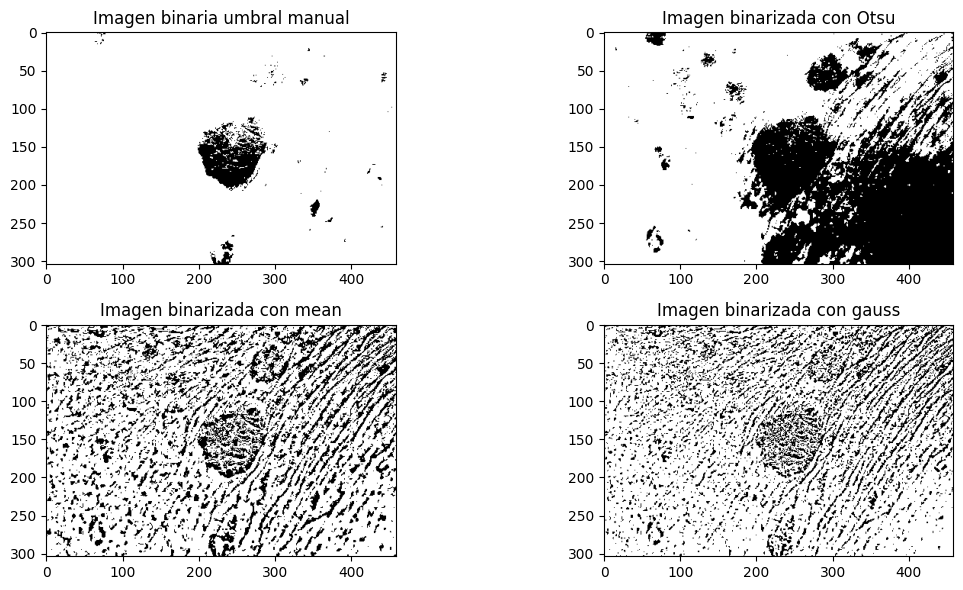

In [ ]:
plt.figure(figsize=(12, 6))


plt.subplot(2, 2, 1)
plt.imshow(binaria, cmap='gray')
plt.title('Imagen binaria umbral manual')

plt.subplot(2, 2, 2)
plt.imshow(binaria_o, cmap='gray')
plt.title('Imagen binarizada con Otsu')

plt.subplot(2, 2, 3)
plt.imshow(binaria_m, cmap='gray')
plt.title('Imagen binarizada con mean')
plt.subplot(2, 2, 4)
plt.imshow(binaria_g, cmap='gray')
plt.title('Imagen binarizada con gauss')
#plt.xlim([0, 256])
#plt.ylim([0, 2000]) #jugamos aca con los limites del eje y
plt.tight_layout()
plt.show()